# Sustainable Multi-Objective Supply Chain Network Optimisation
### A deterministic mixed-integer programming study of economic efficiency, emissions, service feasibility, and disruption response

**Study type:** Master's-level computational Operations Research project  
**Methods:** Mixed-integer linear programming (MILP), ε-constraint multi-objective analysis, policy sensitivity, and deterministic stress testing  
**Implementation:** Python, PuLP, CBC, Pandas, NumPy, and Matplotlib

---

## Study overview

The design of a manufacturing and distribution network requires coordinated decisions about facility capacity, production allocation, and inter-regional shipments. A cost-efficient network may have a substantial emissions footprint, while environmental or service requirements can alter the optimal configuration or make the problem infeasible. This study examines those interactions through a stylised five-country model covering the **USA, Germany, Japan, Brazil, and India**.

The analysis begins with a cost-minimising network design and uses that solution as the reference for controlled computational experiments. The subsequent analyses examine the attainable emissions reduction, the economic implications of emissions caps and carbon prices, the feasibility of uniform delivery-time restrictions, the remaining capacity headroom, and the response to increased freight costs.

### Research questions

1. **Economic network design:** Which facility-size selections and international shipment flows minimise the modelled monthly cost while satisfying demand and capacity constraints?
2. **Environmental performance:** What cost–emissions trade-offs arise when progressively stricter carbon budgets are imposed?
3. **Policy sensitivity:** How does an explicit carbon price influence the optimal network configuration across the tested policy levels?
4. **Operational feasibility:** How do lead-time restrictions and uniform demand growth affect model feasibility?
5. **Disruption response:** How do the optimal cost, emissions, and regional production allocation change under a substantial freight-cost increase?

### Scope and interpretation

The model uses the supplied tabular data and solves **deterministic, single-period scenarios**. Its outputs are conditional on those inputs and modelling assumptions; they are not forecasts for an identified real-world firm. Stress tests are performed by **reoptimising** the network after a parameter change. They should therefore not be interpreted as a stochastic or formal robust-optimisation design.

**Reproducibility note:** All existing Python cells and relative Excel paths are retained without modification in this documented version. The notebook expects its original `../Datasets/` directory structure.


## 1. Computational environment and network data

### 1.1 Optimisation approach

The network-design problem is formulated as a **mixed-integer linear program (MILP)** and solved using the CBC solver accessed through PuLP. The formulation combines two decision types:

- **Binary facility decisions**, representing the selection of a plant-capacity option in a candidate country.
- **Continuous shipment-flow decisions**, representing the quantity supplied from an origin country to a destination market.

The following cell imports the numerical, optimisation, and visualisation libraries required throughout the analysis. The subsequent cell loads the **nine original Excel inputs**, including the delivery-deadline table, without changing their filenames or relative paths.

### 1.2 Input-data representation

The input matrices describe manufacturing costs, transport costs, storage costs, fixed facility costs, candidate capacities, regional demand, route emissions factors, and delivery lead times. Countries form the common geographical index for origin–destination relationships. Two facility-size options—**Low** and **High**—are available for each country.

The delivery-deadline table is loaded for completeness, but the service experiment later in this notebook uses a **single uniform route lead-time limit** evaluated against `delivery_times`; the imported `del_deadline` matrix is not imposed as an independent set of constraints.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pulp
from pulp import (
    LpProblem,
    LpMinimize,
    LpVariable,
    LpStatus,
    lpSum,
    value,
    PULP_CBC_CMD
)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("PuLP version:", pulp.__version__)


PuLP version: 3.3.2


In [2]:
# IMPORTANT: Original file paths retained exactly as provided.
var_costs = pd.read_excel('../Datasets/variable_costs.xlsx', index_col=0)
freight_costs = pd.read_excel('../Datasets/freight_costs.xlsx', index_col=0)
storage_costs = pd.read_excel('../Datasets/Storage_costs.xlsx', index_col=0)
carbon_emissions = pd.read_excel('../Datasets/CO2_Emissions.xlsx', index_col=0)
delivery_times = pd.read_excel('../Datasets/Delivery_LeadTime.xlsx', index_col=0)
fixed_costs = pd.read_excel('../Datasets/fixed_cost.xlsx', index_col=0)
capacity = pd.read_excel('../Datasets/capacity.xlsx', index_col=0)
demand = pd.read_excel('../Datasets/demand.xlsx', index_col=0)
del_deadline = pd.read_excel('../Datasets/Delivery_Deadlines.xlsx', index_col=0)

loc = ['USA', 'Germany', 'Japan', 'Brazil', 'India']
size = ['Low', 'High']

total_costs = freight_costs / 1000 + var_costs
total_fixed_costs = fixed_costs + storage_costs

print("Data loaded successfully.")
print(f"Countries: {len(loc)} | Candidate plant decisions: {len(loc) * len(size)} | Shipping routes: {len(loc)**2}")

Data loaded successfully.
Countries: 5 | Candidate plant decisions: 10 | Shipping routes: 25


## 2. Input-data inspection and elementary consistency checks

Reliable optimisation begins with verifying the structure of the supplied input data. The following diagnostic cell reports matrix dimensions, missing observations, and numeric data types for the eight inputs used in the validation table. It then computes total demand, an aggregate upper bound on installable capacity, and the corresponding nominal capacity headroom.

These tests are **preliminary data-integrity checks**: they establish that the inspected tables have numeric, non-missing entries, but they do not independently validate economic units, emissions-factor provenance, physical plausibility, or the consistency of every row/column label.

### Questions addressed

- Are the numerical input matrices complete enough to construct the MILP?
- What is the aggregate demand to be satisfied in the baseline scenario?
- How much capacity could be installed if the highest capacity option were selected in every country?

**Important distinction:** Aggregate capacity greater than demand is necessary for feasibility, but it does not on its own guarantee feasibility when additional routing or service constraints are active.


In [3]:
datasets = {
    "Variable costs": var_costs,
    "Freight costs": freight_costs,
    "Storage costs": storage_costs,
    "CO2 emissions": carbon_emissions,
    "Delivery times": delivery_times,
    "Fixed costs": fixed_costs,
    "Capacity": capacity,
    "Demand": demand,
}

validation = []

for name, df in datasets.items():
    validation.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing values": int(df.isna().sum().sum()),
        "Numeric": bool(all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)),
    })

validation_df = pd.DataFrame(validation)
display(validation_df)

assert validation_df["Missing values"].sum() == 0, "Missing values detected in the input data."
assert validation_df["Numeric"].all(), "Non-numeric values detected in optimization inputs."

total_demand = float(demand["Demand"].sum())
maximum_capacity = float(capacity["High"].sum() * 1000)

print(f"Total monthly demand: {total_demand:,.0f} units")
print(f"Maximum installed network capacity: {maximum_capacity:,.0f} units")
print(f"Nominal capacity headroom: {(maximum_capacity / total_demand - 1) * 100:.2f}%")

,Dataset,Rows,Columns,Missing values,Numeric
0,Variable costs,5,5,0,True
1,Freight costs,5,5,0,True
2,Storage costs,5,2,0,True
3,CO2 emissions,5,5,0,True
4,Delivery times,5,5,0,True
5,Fixed costs,5,2,0,True
6,Capacity,5,2,0,True
7,Demand,5,1,0,True


Total monthly demand: 4,895,000 units
Maximum installed network capacity: 5,000,000 units
Nominal capacity headroom: 2.15%


**Data-check observation.** The displayed tables contain no missing or non-numeric values in the eight inspected optimisation inputs. Total monthly demand is **4,895,000 units** and the stated maximum installable capacity is **5,000,000 units**, giving approximately **2.15% aggregate headroom**. This is a capacity accounting result, not a guarantee that every further constraint set is feasible.


## 3. Mathematical model: capacitated facility location and inter-country flows

### 3.1 Decision structure

The model jointly determines which candidate plant sizes are selected and how much product moves between each manufacturing origin and destination market. Strategic facility-size choices are discrete; operational material flows are continuous. The original notation and governing expressions are retained below without modification.

Let:

- $(x_{ij})$: units manufactured in country \(i\) and supplied to country \(j\)
- $(y_{is})$: binary decision indicating whether plant size \(s\) is opened in country \(i\)

### Economic objective

$$
\min C =
\sum_{i,s}F_{is}y_{is}
+
\sum_{i,j}c_{ij}x_{ij}
+
p_c\frac{E}{1000}
$$

where $(p_c)$ is an optional carbon price in **$/tCO₂** and

$$
E = \sum_{i,j} e_{ij}x_{ij}
$$

is network CO₂ emissions in kg according to the supplied emission factors.

### Constraints

1. Demand must be satisfied in every market.
2. Production cannot exceed installed plant capacity.
3. At most one plant-capacity option can be selected per country.
4. An optional carbon budget may constrain total network emissions.
5. An optional service-level threshold may forbid routes exceeding a specified lead time.

### 3.2 Implementation and scenario controls

The implementation constructs a single economic objective from fixed/storage-related facility costs, variable manufacturing and freight costs, and an **optional** carbon-price contribution. Regional demands must be met exactly; installed production capacity limits outflows; and no more than one plant-size option may be selected per country.

Optional controls activate either a network-wide emissions cap or a uniform lead-time cutoff. These features allow the same baseline model to be used across the policy and service analyses without changing its core facility/flow decision variables.

**Unit convention:** The code constructs emissions in kg CO₂ and converts to tonnes when applying a carbon price expressed in $/tCO₂. Economic `total_cost` is reported separately from the tax-inclusive objective when carbon pricing is active.

**Service modelling note:** The route cutoff is optional because the 30-day uniform limit is infeasible in the tested configuration. The imported deadline table is not separately enforced in this function.


In [4]:
def solve_supply_chain(
    demand_df=None,
    freight_multiplier=1.0,
    carbon_cap_kg=None,
    carbon_price_per_ton=0.0,
    max_lead_days=None,
    solver_msg=False,
):
    """Solve one supply-chain network-design scenario."""

    demand_df = demand.copy() if demand_df is None else demand_df.copy()

    scenario_total_costs = var_costs + (freight_costs * freight_multiplier) / 1000

    model = LpProblem("Sustainable_Supply_Chain_Network", LpMinimize)

    flow = LpVariable.dicts(
        "flow",
        [(i, j) for i in loc for j in loc],
        lowBound=0,
        cat="Continuous"
    )

    plant = LpVariable.dicts(
        "plant",
        [(i, s) for i in loc for s in size],
        cat="Binary"
    )

    fixed_cost_expr = lpSum(
        float(total_fixed_costs.loc[i, s]) * 1000 * plant[(i, s)]
        for i in loc for s in size
    )

    operating_cost_expr = lpSum(
        float(scenario_total_costs.loc[i, j]) * flow[(i, j)]
        for i in loc for j in loc
    )

    emissions_expr = lpSum(
        float(carbon_emissions.loc[i, j]) * flow[(i, j)]
        for i in loc for j in loc
    )

    # Convert kg CO2 to tonnes before applying a $/tCO2 carbon price.
    carbon_cost_expr = float(carbon_price_per_ton) * emissions_expr / 1000

    model += fixed_cost_expr + operating_cost_expr + carbon_cost_expr

    # Demand satisfaction.
    for j in loc:
        model += (
            lpSum(flow[(i, j)] for i in loc) == float(demand_df.loc[j, "Demand"]),
            f"Demand_{j}"
        )

    # Capacity and plant-selection constraints.
    for i in loc:
        model += (
            lpSum(flow[(i, j)] for j in loc)
            <= lpSum(
                float(capacity.loc[i, s]) * 1000 * plant[(i, s)]
                for s in size
            ),
            f"Capacity_{i}"
        )

        model += (
            lpSum(plant[(i, s)] for s in size) <= 1,
            f"PlantChoice_{i}"
        )

    # Optional route-level service constraint.
    if max_lead_days is not None:
        for i in loc:
            for j in loc:
                if float(delivery_times.loc[i, j]) > float(max_lead_days):
                    model += flow[(i, j)] == 0, f"LeadTime_{i}_{j}"

    # Optional network-level carbon budget.
    if carbon_cap_kg is not None:
        if not np.isfinite(carbon_cap_kg):
            raise ValueError(f"carbon_cap_kg must be finite; received {carbon_cap_kg}")
        model += emissions_expr <= float(carbon_cap_kg), "NetworkCarbonBudget"

    model.solve(PULP_CBC_CMD(msg=solver_msg))
    status = LpStatus[model.status]

    if status != "Optimal":
        return {
            "status": status,
            "total_cost": np.nan,
            "total_emissions_kg": np.nan,
            "objective_with_carbon_price": np.nan,
            "flows": pd.DataFrame(index=loc, columns=loc, dtype=float),
            "plants": pd.DataFrame(index=loc, columns=size, dtype=float),
        }

    flow_df = pd.DataFrame(
        {
            j: [value(flow[(i, j)]) for i in loc]
            for j in loc
        },
        index=loc
    )

    plant_df = pd.DataFrame(
        {
            s: [value(plant[(i, s)]) for i in loc]
            for s in size
        },
        index=loc
    )

    fixed_cost_value = sum(
        float(total_fixed_costs.loc[i, s]) * 1000 * value(plant[(i, s)])
        for i in loc for s in size
    )

    operating_cost_value = sum(
        float(scenario_total_costs.loc[i, j]) * value(flow[(i, j)])
        for i in loc for j in loc
    )

    emissions_value = sum(
        float(carbon_emissions.loc[i, j]) * value(flow[(i, j)])
        for i in loc for j in loc
    )

    return {
        "status": status,
        "total_cost": fixed_cost_value + operating_cost_value,
        "total_emissions_kg": emissions_value,
        "objective_with_carbon_price": value(model.objective),
        "flows": flow_df,
        "plants": plant_df,
    }

## 4. Economic baseline: minimum-cost network configuration

### Experimental purpose

The first optimisation solves the deterministic network under the supplied demand and capacity assumptions, **without an emissions cap, carbon price, or uniform delivery-time restriction**. This result is the economic reference point against which all subsequent scenarios are compared.

### Outputs examined

- Optimal solver status and modelled monthly economic cost.
- Total network emissions associated with the cost-optimal flows.
- Selected plant-capacity option in each country.
- Origin–destination shipment matrix and the resulting production allocation by manufacturing country.

This separation between the economic and environmental performance of the same solution is essential: minimising cost does not, in general, minimise emissions. In this model, baseline monetary costs and network emissions are therefore recorded separately.


In [5]:
baseline = solve_supply_chain()

if baseline["status"] != "Optimal":
    raise RuntimeError(f"Baseline model failed: {baseline['status']}")

print("Status:", baseline["status"])
print(f"Baseline monthly network cost: ${baseline['total_cost']:,.2f}")
print(f"Baseline CO2 emissions: {baseline['total_emissions_kg']/1000:,.2f} tCO2")

print("\nPlant-capacity decisions:")
display(baseline["plants"])

print("\nOptimal inter-country flows:")
display(baseline["flows"])

Status: Optimal
Baseline monthly network cost: $116,602,891.67
Baseline CO2 emissions: 455,604.01 tCO2

Plant-capacity decisions:


,Low,High
USA,0.000,1.000
Germany,0.000,1.000
Japan,0.000,1.000
Brazil,0.000,1.000
India,0.000,1.000



Optimal inter-country flows:


,USA,Germany,Japan,Brazil,India
USA,"1,000,000.000",0.000,0.000,0.000,0.000
Germany,"105,000.000","90,000.000","700,000.000",0.000,0.000
Japan,0.000,0.000,"1,000,000.000",0.000,0.000
Brazil,"855,000.000",0.000,0.000,"145,000.000",0.000
India,"840,000.000",0.000,0.000,0.000,"160,000.000"


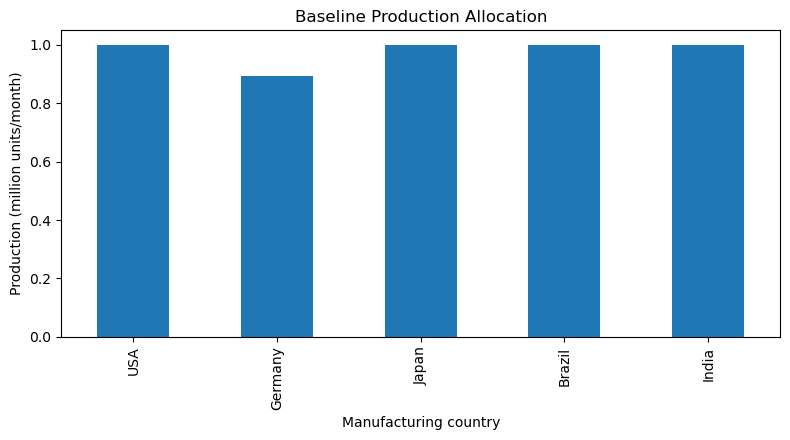

In [6]:
origin_output = baseline["flows"].sum(axis=1) / 1_000_000

fig, ax = plt.subplots(figsize=(8, 4.5))
origin_output.plot(kind="bar", ax=ax)
ax.set_title("Baseline Production Allocation")
ax.set_xlabel("Manufacturing country")
ax.set_ylabel("Production (million units/month)")
plt.tight_layout()
plt.show()

### Baseline result and discussion

The saved solution reports an **optimal monthly cost of approximately $116.60 million** and **455,604.01 tCO₂** of modelled network emissions. In the resulting plant-selection table, the **High** capacity option is selected in all five countries. The shipment matrix shows that satisfying regional demand involves both domestic production and international supply flows.

The production-allocation figure provides a geographical summary of the same optimisation solution; no independent network-performance model is introduced here. These baseline values are used consistently as reference denominators in the later scenario analyses.


## 5. Environmental reference solution: minimum attainable emissions

### Rationale

The cost-optimal network provides one endpoint for studying the economic–environmental trade-off. To construct the other reference endpoint, this section **minimises modelled CO₂ emissions subject to the same basic demand, capacity, and plant-selection structure**, without treating monetary cost as the objective.

The resulting minimum is a **model-conditional lower bound** on emissions for the candidate network and its input coefficients. It does not establish a technological or life-cycle minimum for real supply chains, nor does it account for uncertainty in emissions factors.

### Interpretation

Comparing the minimum-emissions solution with the cost-optimal baseline quantifies the maximum modelled percentage reduction available **within the existing deterministic formulation**. The next section then evaluates the cost necessary to achieve intermediate emissions levels.


In [7]:
def solve_minimum_emissions(solver_msg=False):
    model = LpProblem("Minimum_Emission_Network", LpMinimize)

    flow = LpVariable.dicts(
        "flow",
        [(i, j) for i in loc for j in loc],
        lowBound=0,
        cat="Continuous"
    )

    plant = LpVariable.dicts(
        "plant",
        [(i, s) for i in loc for s in size],
        cat="Binary"
    )

    emissions_expr = lpSum(
        float(carbon_emissions.loc[i, j]) * flow[(i, j)]
        for i in loc for j in loc
    )

    model += emissions_expr

    for j in loc:
        model += lpSum(flow[(i, j)] for i in loc) == float(demand.loc[j, "Demand"])

    for i in loc:
        model += (
            lpSum(flow[(i, j)] for j in loc)
            <= lpSum(
                float(capacity.loc[i, s]) * 1000 * plant[(i, s)]
                for s in size
            )
        )
        model += lpSum(plant[(i, s)] for s in size) <= 1

    model.solve(PULP_CBC_CMD(msg=solver_msg))
    status = LpStatus[model.status]

    if status != "Optimal":
        raise RuntimeError(f"Minimum-emission model failed: {status}")

    minimum_emissions = value(emissions_expr)

    if minimum_emissions is None or not np.isfinite(minimum_emissions):
        raise ValueError(f"Invalid minimum-emission value: {minimum_emissions}")

    return float(minimum_emissions)


minimum_emissions_kg = solve_minimum_emissions()
baseline_emissions_kg = float(baseline["total_emissions_kg"])

print(f"Minimum technically feasible emissions: {minimum_emissions_kg/1000:,.2f} tCO2")
print(f"Cost-optimal baseline emissions: {baseline_emissions_kg/1000:,.2f} tCO2")
print(
    f"Maximum technically feasible reduction: "
    f"{100*(1-minimum_emissions_kg/baseline_emissions_kg):.2f}%"
)

Minimum technically feasible emissions: 279,563.69 tCO2
Cost-optimal baseline emissions: 455,604.01 tCO2
Maximum technically feasible reduction: 38.64%


**Environmental reference result.** The minimum-emissions formulation gives approximately **279,563.69 tCO₂**, compared with **455,604.01 tCO₂** under the cost-minimising baseline—equivalent to a **38.64% modelled reduction**. This is the extremal value for the specified candidate network and emissions coefficients; the economic consequences are evaluated next.


## 6. Bi-objective analysis: cost–carbon trade-offs using the ε-constraint method

### Decision problem

Supply-chain sustainability creates a trade-off between economic expenditure and CO₂ emissions. Rather than combine the two objectives using an arbitrary fixed weight, the analysis applies an **ε-constraint approach**: economic cost remains the optimisation objective, while network emissions are restricted by a sequence of progressively tighter budgets.

The notebook evaluates **15 specified carbon-cap levels** between the minimum-emissions reference and the baseline-emissions reference. For each feasible cap, the MILP returns the least-cost network permitted by that budget. The resulting sampled solutions characterise the model's attainable cost–emissions trade-offs.

### Evaluation measures

- **Emissions reduction (%):** reduction relative to the cost-optimal baseline emissions.
- **Cost premium (%):** increase in modelled economic cost relative to the baseline economic cost.
- **Feasibility:** whether the MILP has an optimal solution at a given carbon cap.

The sampled points constitute a **discrete approximation of the trade-off frontier** over the chosen caps, not an exhaustive representation of every possible efficient solution. Numerical values should be interpreted within solver tolerances.


In [8]:
carbon_caps = np.linspace(minimum_emissions_kg, baseline_emissions_kg, 15)

pareto_records = []

for cap_kg in carbon_caps:
    result = solve_supply_chain(carbon_cap_kg=float(cap_kg))

    if result["status"] == "Optimal":
        pareto_records.append({
            "Carbon Cap (tCO2)": cap_kg / 1000,
            "Cost ($/month)": result["total_cost"],
            "Emissions (tCO2)": result["total_emissions_kg"] / 1000,
            "Cost Premium (%)":
                100 * (result["total_cost"] / baseline["total_cost"] - 1),
            "CO2 Reduction (%)":
                100 * (1 - result["total_emissions_kg"] / baseline_emissions_kg),
        })

pareto_df = pd.DataFrame(pareto_records)

if pareto_df.empty:
    raise RuntimeError("No feasible Pareto solutions were generated.")

display(pareto_df.round(3))

,Carbon Cap (tCO2),Cost ($/month),Emissions (tCO2),Cost Premium (%),CO2 Reduction (%)
0,"279,563.694","128,307,416.667","279,563.694",10.038,38.639
1,"292,138.002","127,255,437.564","292,138.002",9.136,35.879
2,"304,712.310","126,429,232.954","304,712.310",8.427,33.119
3,"317,286.619","125,603,028.630","317,286.618",7.719,30.359
4,"329,860.927","124,776,824.128","329,860.927",7.010,27.599
5,"342,435.235","123,950,619.781","342,435.234",6.301,24.839
6,"355,009.543","123,124,415.279","355,009.544",5.593,22.079
7,"367,583.851","122,298,210.933","367,583.851",4.884,19.319
8,"380,158.159","121,472,006.587","380,158.158",4.176,16.560
9,"392,732.468","120,645,802.085","392,732.468",3.467,13.800


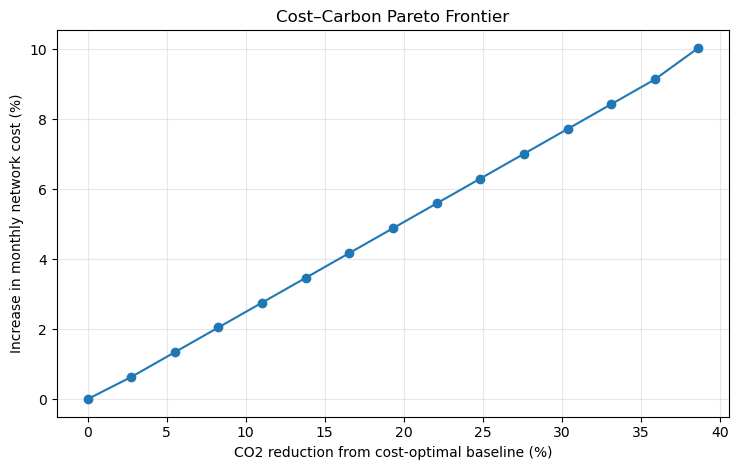

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(
    pareto_df["CO2 Reduction (%)"],
    pareto_df["Cost Premium (%)"],
    marker="o"
)
ax.set_title("Cost–Carbon Pareto Frontier")
ax.set_xlabel("CO2 reduction from cost-optimal baseline (%)")
ax.set_ylabel("Increase in monthly network cost (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpreting the sampled trade-off curve

The 15-point sweep shows that tightening the carbon budget raises the minimum economic cost relative to the unconstrained baseline. At the minimum-emissions endpoint, the table reports a **38.64% reduction** at a **10.04% increase in modelled monthly economic cost**. The plot displays the trade-off in percentage terms so the economic and environmental changes can be compared on a consistent basis.

These are **optimised network outcomes under alternative deterministic caps**. They do not imply that the same plant/flow design remains optimal for all cap values.


In [10]:
# Identify a normalized best-compromise point (closest to the utopia point:
# maximum emission reduction and minimum cost premium).

cost_norm = (
    pareto_df["Cost Premium (%)"] - pareto_df["Cost Premium (%)"].min()
) / max(
    pareto_df["Cost Premium (%)"].max() - pareto_df["Cost Premium (%)"].min(),
    1e-12
)

reduction_norm = (
    pareto_df["CO2 Reduction (%)"] - pareto_df["CO2 Reduction (%)"].min()
) / max(
    pareto_df["CO2 Reduction (%)"].max() - pareto_df["CO2 Reduction (%)"].min(),
    1e-12
)

distance_to_utopia = np.sqrt(cost_norm**2 + (1 - reduction_norm)**2)
compromise_idx = distance_to_utopia.idxmin()
compromise = pareto_df.loc[compromise_idx]

print("Normalized compromise solution:")
display(compromise.to_frame("Value").round(3))

Normalized compromise solution:


,Value
Carbon Cap (tCO2),"367,583.851"
Cost ($/month),"122,298,210.933"
Emissions (tCO2),"367,583.851"
Cost Premium (%),4.884
CO2 Reduction (%),19.319


### Illustrative compromise selection

The notebook also selects a solution by minimising the Euclidean distance to a **normalised ideal point** in the two-dimensional space of cost premium and emissions reduction. Under this **specific normalisation and compromise rule**, the selected sample achieves approximately **19.32% lower emissions** at a **4.88% economic cost premium** relative to the baseline.

This is a transparent **decision-support heuristic**, not a unique or preference-free definition of the best sustainable network. Different policy preferences or objective scaling can select a different point on the same frontier.


## 7. Environmental policy experiment: carbon-price sensitivity

### Policy mechanism

Whereas an emissions cap explicitly restricts the feasible region, a **carbon price modifies the economic objective** by assigning a monetary cost to modelled emissions. The underlying facility and shipment constraints remain otherwise unchanged. The original policy-cost expression is reproduced here verbatim:

$$
\text{Carbon cost} =
p_c \times \frac{E_{\mathrm{kg}}}{1000}
$$

The carbon price is specified in **$/tCO₂**, while network emissions are computed in **kg CO₂**. The code therefore converts emission units before adding the policy charge to the optimisation objective.

### Experimental design and interpretation

The notebook evaluates the discrete price grid **$0, $25, $50, $75, $100, $150, and $200 per tCO₂**. The resulting table reports the economic network cost **excluding the carbon-price payment**, as well as emissions and their change relative to the zero-price baseline; the **optimisation decision itself includes the carbon payment**.

Because plant-size choices are discrete, changes in the optimum may be non-smooth as the policy price varies. The **first price at which the tested solutions differ from the baseline** is a sampled response point—not a precisely estimated theoretical breakpoint.


In [11]:
carbon_prices = [0, 25, 50, 75, 100, 150, 200]

carbon_price_records = []
carbon_price_solutions = {}

for price in carbon_prices:
    result = solve_supply_chain(carbon_price_per_ton=price)
    carbon_price_solutions[price] = result

    if result["status"] == "Optimal":
        carbon_price_records.append({
            "Carbon Price ($/tCO2)": price,
            "Network Cost excluding carbon ($/month)": result["total_cost"],
            "Emissions (tCO2)": result["total_emissions_kg"] / 1000,
            "CO2 Reduction (%)":
                100 * (1 - result["total_emissions_kg"] / baseline_emissions_kg),
        })

carbon_price_df = pd.DataFrame(carbon_price_records)
display(carbon_price_df.round(3))

,Carbon Price ($/tCO2),Network Cost excluding carbon ($/month),Emissions (tCO2),CO2 Reduction (%)
0,0,"116,602,891.667","455,604.008",0.000
1,25,"116,602,891.667","455,604.008",0.000
2,50,"116,800,816.667","451,250.712",0.956
3,75,"127,698,416.667","285,396.138",37.359
4,100,"127,698,416.667","285,396.138",37.359
5,150,"128,307,416.667","279,563.694",38.639
6,200,"128,307,416.667","279,563.694",38.639


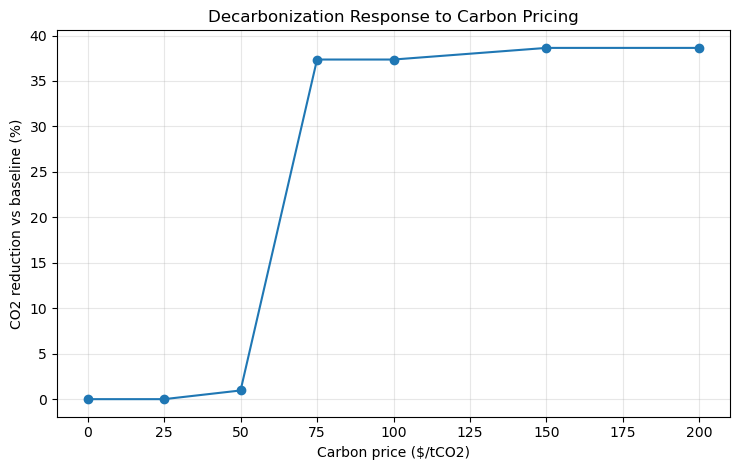

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(
    carbon_price_df["Carbon Price ($/tCO2)"],
    carbon_price_df["CO2 Reduction (%)"],
    marker="o"
)
ax.set_title("Decarbonization Response to Carbon Pricing")
ax.set_xlabel("Carbon price ($/tCO2)")
ax.set_ylabel("CO2 reduction vs baseline (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Carbon-price result and policy interpretation

Across the tested grid, the **first observed change** from the zero-price configuration occurs at **\$50/tCO₂**; the 25 $/tCO₂ case retains the baseline emissions level. Stronger responses appear at other sampled levels, reflecting discrete changes in the optimised network. For example, the table reports a reduction of approximately **37.36\%** at **\$75/tCO₂** and **38.64\%** at **\$150/tCO₂**.

Because the experiment uses only seven prices, these values **do not localise exact switching thresholds**. The cost table excludes the carbon charge when reporting the underlying economic operating cost, so policy-inclusive expenditure should not be inferred directly from that column.


## 8. Service constraints: feasibility of a uniform route lead-time allowance

### Operational motivation

Service commitments can rule out routes that are attractive on cost grounds. Here, the MILP excludes each origin–destination flow whose delivery lead time exceeds a specified **uniform maximum allowable lead time**. The notebook solves the resulting problem at each distinct lead-time value present in the route matrix.

The experiment answers a precise feasibility question: **what is the smallest tested route-time threshold for which demand can still be satisfied with the candidate facilities and capacities?**

### Experimental interpretation

An infeasible result means that **no admissible facility/flow combination exists under the particular uniform cutoff and current model**, not that the supply chain could never operate in practice. Because the code applies a single threshold to all routes, these results should not be described as enforcing the separate destination-specific deadlines in the imported `Delivery_Deadlines.xlsx` file.

The service constraint represents **route eligibility**, not an explicitly modelled distribution of delivery delays or on-time delivery probabilities.


In [13]:
candidate_lead_limits = sorted(np.unique(delivery_times.to_numpy().astype(float)))

lead_records = []

for limit in candidate_lead_limits:
    result = solve_supply_chain(max_lead_days=float(limit))
    lead_records.append({
        "Maximum Allowed Lead Time (days)": limit,
        "Status": result["status"],
        "Cost ($/month)": result["total_cost"],
        "Emissions (tCO2)":
            result["total_emissions_kg"] / 1000
            if result["status"] == "Optimal" else np.nan,
    })

lead_df = pd.DataFrame(lead_records)
display(lead_df)

feasible_lead_df = lead_df[lead_df["Status"] == "Optimal"]

if not feasible_lead_df.empty:
    minimum_feasible_lead = feasible_lead_df.iloc[0]["Maximum Allowed Lead Time (days)"]
    print(f"Minimum feasible uniform lead-time allowance: {minimum_feasible_lead:.0f} days")
else:
    print("No feasible lead-time threshold found in the supplied route matrix.")

,Maximum Allowed Lead Time (days),Status,Cost ($/month),Emissions (tCO2)
0,3.000,Infeasible,NaN,NaN
1,21.000,Infeasible,NaN,NaN
2,29.000,Infeasible,NaN,NaN
3,30.000,Infeasible,NaN,NaN
4,33.000,Infeasible,NaN,NaN
5,34.000,Optimal,"128,835,391.667","281,394.224"
6,41.000,Optimal,"127,500,491.667","289,749.435"
7,43.000,Optimal,"127,500,491.667","289,749.435"
8,59.000,Optimal,"116,602,891.667","455,604.008"
9,62.000,Optimal,"116,602,891.667","455,604.008"


Minimum feasible uniform lead-time allowance: 34 days


### Service-feasibility result

A **30-day uniform route threshold is infeasible** in the tested network, as are the other sampled cutoffs below **34 days**. The **smallest feasible threshold among the tested distinct route times is 34 days**. At that setting, the reported cost is approximately **$128.84 million/month** and the modelled emissions are **281,394.22 tCO₂**.

This result quantifies the economic and feasibility implications of restricting the set of admissible routes. It is conditional on the supplied route times and available capacity options; it does not measure probabilistic on-time performance.


## 9. Demand-growth stress test and aggregate capacity headroom

### Motivation

A network designed near its capacity ceiling may have limited scope to absorb additional demand. To diagnose this limitation, the analysis applies **uniform proportional growth** to all destination demands while retaining the same candidate facility options and input costs.

The calculation proceeds in two steps:

1. Compute the **theoretical aggregate capacity headroom** from the ratio of maximum installable capacity to baseline demand.
2. Resolve the MILP for selected demand-growth levels, including values immediately below, at, and above that theoretical headroom.

### Important methodological distinction

The aggregate ratio is an **upper bound derived from total capacity**; it is not a demonstrated operational growth limit. A scenario at the numerical boundary can behave differently from the aggregate calculation because the optimisation model is subject to additional constraints and solver tolerances. The results below therefore report **calculated headroom and observed MILP feasibility separately**.

These are deterministic feasibility experiments, not probability-based demand-risk estimates.


In [14]:
theoretical_growth_limit = maximum_capacity / total_demand - 1

print(f"Theoretical uniform demand-growth limit: {theoretical_growth_limit*100:.2f}%")

growth_tests = [0.00, 0.01, 0.02, theoretical_growth_limit, theoretical_growth_limit + 0.001]

growth_records = []

for growth in growth_tests:
    scenario_demand = demand.copy()
    scenario_demand["Demand"] = demand["Demand"] * (1 + growth)

    result = solve_supply_chain(demand_df=scenario_demand)

    growth_records.append({
        "Demand Growth (%)": growth * 100,
        "Status": result["status"],
        "Cost ($/month)": result["total_cost"],
        "Emissions (tCO2)":
            result["total_emissions_kg"] / 1000
            if result["status"] == "Optimal" else np.nan,
    })

growth_df = pd.DataFrame(growth_records)
display(growth_df.round(3))

Theoretical uniform demand-growth limit: 2.15%


,Demand Growth (%),Status,Cost ($/month),Emissions (tCO2)
0,0.000,Optimal,"116,602,891.667","455,604.008"
1,1.000,Optimal,"117,754,089.917","462,292.543"
2,2.000,Optimal,"118,905,288.167","468,981.077"
3,2.145,Infeasible,NaN,NaN
4,2.245,Infeasible,NaN,NaN


### Capacity-feasibility result and numerical caveat

The notebook computes **2.145%** as the aggregate theoretical limit from total candidate capacity. The MILP reports **Optimal** at **0%, 1%, and 2%** uniform demand growth, but **Infeasible** at the exact calculated aggregate boundary (approximately **2.145%**) and at **2.245%**.

Accordingly, the supported conclusion is that **2% growth was feasible in the tested runs**, while approximately **2.15% is only an aggregate upper bound**. The precise reason for infeasibility at the calculated boundary is not established in the notebook; solver tolerances and boundary feasibility would require additional diagnostic work. The present results should not be reported as proof that 2.15% growth is operationally feasible.


## 10. Freight-cost disruption: comparative-static network reoptimisation

### Scenario definition

This experiment represents a stylised logistics-cost shock by multiplying the model's freight-cost coefficients by **three** and solving the MILP again. Demand, candidate facilities, and other input relationships are otherwise retained in the same modelling framework.

### Performance indicators

The disruption scenario is compared with the original economic baseline using:

- Total modelled monthly network cost and its percentage change.
- Modelled CO₂ emissions and their percentage change.
- Reallocation of production volumes across the five countries.

### Modelling boundary

The exercise permits **facility and shipment decisions to be reoptimised after the shock is specified**. It quantifies the response of an adaptable deterministic model; it does **not** measure the cost of a fixed pre-disruption facility configuration, implementation lead times, or the benefits of a two-stage recourse policy. Those distinctions motivate future stochastic and robust network-design formulations.


In [15]:
freight_shock = solve_supply_chain(freight_multiplier=3.0)

if freight_shock["status"] != "Optimal":
    raise RuntimeError(f"Freight-shock model failed: {freight_shock['status']}")

stress_summary = pd.DataFrame([
    {
        "Scenario": "Baseline",
        "Cost ($/month)": baseline["total_cost"],
        "Emissions (tCO2)": baseline["total_emissions_kg"] / 1000,
    },
    {
        "Scenario": "3× Freight Cost",
        "Cost ($/month)": freight_shock["total_cost"],
        "Emissions (tCO2)": freight_shock["total_emissions_kg"] / 1000,
    },
])

stress_summary["Cost Change (%)"] = (
    stress_summary["Cost ($/month)"] / baseline["total_cost"] - 1
) * 100

stress_summary["CO2 Change (%)"] = (
    stress_summary["Emissions (tCO2)"] /
    (baseline["total_emissions_kg"] / 1000) - 1
) * 100

display(stress_summary.round(3))

,Scenario,Cost ($/month),Emissions (tCO2),Cost Change (%),CO2 Change (%)
0,Baseline,"116,602,891.667","455,604.008",0.000,0.000
1,3× Freight Cost,"182,072,316.667","451,250.712",56.147,-0.956


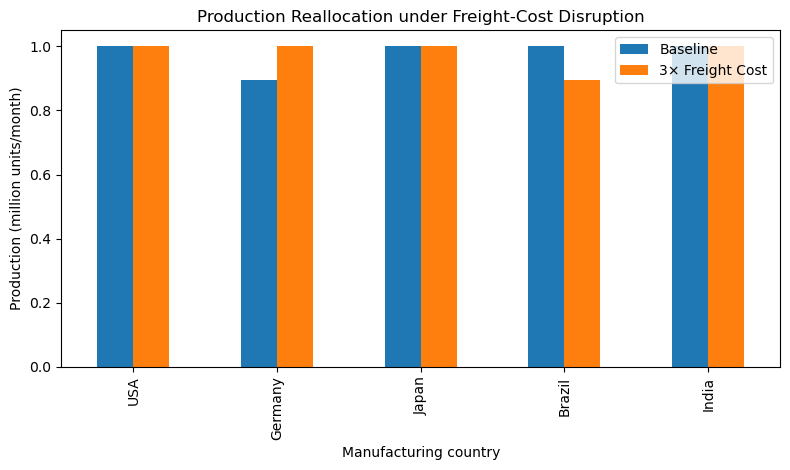

,Baseline,3× Freight Cost
USA,1.000,1.000
Germany,0.895,1.000
Japan,1.000,1.000
Brazil,1.000,0.895
India,1.000,1.000


In [16]:
production_comparison = pd.DataFrame({
    "Baseline": baseline["flows"].sum(axis=1) / 1_000_000,
    "3× Freight Cost": freight_shock["flows"].sum(axis=1) / 1_000_000,
})

ax = production_comparison.plot(kind="bar", figsize=(8, 4.8))
ax.set_title("Production Reallocation under Freight-Cost Disruption")
ax.set_xlabel("Manufacturing country")
ax.set_ylabel("Production (million units/month)")
plt.tight_layout()
plt.show()

display(production_comparison.round(3))

### Freight-disruption result

When freight-cost coefficients are multiplied by three and the network is **fully reoptimised**, total modelled cost increases from approximately **\$116.60 million\/month** to **\$182.07 million/month** (**+56.15\%**). Modelled emissions decrease by approximately **0.96\%** in this specific scenario.

The production comparison shows **Germany increasing from 0.895 to 1.000 million units/month** and **Brazil decreasing from 1.000 to 0.895 million units/month**, while the displayed production totals of the other three countries remain unchanged. This reallocation illustrates the flexibility of the deterministic model to adjust after a specified cost change; it does not quantify real-world switching costs or physical disruption recovery time.


## 11. Consolidated numerical findings

The next cell aggregates the main output measures from the baseline and scenario experiments. Its purpose is to create a compact, auditable record of the computed results without replacing the detailed tables and figures above.

**Interpretation guidance:** The reported 2.15% demand-growth figure is the **theoretical aggregate capacity headroom**, not the largest growth value conclusively shown feasible in the MILP runs. Likewise, the $50/tCO₂ carbon-price result identifies the **first response in the tested price grid**, not an exact mathematical switching threshold.


In [17]:
max_reduction_row = pareto_df.loc[pareto_df["CO2 Reduction (%)"].idxmax()]

first_carbon_response = carbon_price_df[
    carbon_price_df["CO2 Reduction (%)"] > 1e-6
]

if not first_carbon_response.empty:
    carbon_threshold = float(first_carbon_response.iloc[0]["Carbon Price ($/tCO2)"])
else:
    carbon_threshold = np.nan

summary = pd.DataFrame([
    {
        "Metric": "Baseline monthly network cost",
        "Value": f"${baseline['total_cost']:,.2f}",
    },
    {
        "Metric": "Baseline network emissions",
        "Value": f"{baseline['total_emissions_kg']/1000:,.2f} tCO2",
    },
    {
        "Metric": "Maximum modeled CO2 reduction",
        "Value": f"{max_reduction_row['CO2 Reduction (%)']:.2f}%",
    },
    {
        "Metric": "Cost premium at maximum modeled CO2 reduction",
        "Value": f"{max_reduction_row['Cost Premium (%)']:.2f}%",
    },
    {
        "Metric": "Minimum feasible uniform route lead-time",
        "Value": f"{minimum_feasible_lead:.0f} days",
    },
    {
        "Metric": "Theoretical uniform demand-growth headroom",
        "Value": f"{theoretical_growth_limit*100:.2f}%",
    },
    {
        "Metric": "Cost increase under 3× freight shock",
        "Value": f"{(freight_shock['total_cost']/baseline['total_cost']-1)*100:.2f}%",
    },
    {
        "Metric": "First tested carbon price changing the network",
        "Value": (
            f"${carbon_threshold:.0f}/tCO2"
            if np.isfinite(carbon_threshold) else "No response in tested range"
        ),
    },
])

display(summary)

,Metric,Value
0,Baseline monthly network cost,"$116,602,891.67"
1,Baseline network emissions,"455,604.01 tCO2"
2,Maximum modeled CO2 reduction,38.64%
3,Cost premium at maximum modeled CO2 reduction,10.04%
4,Minimum feasible uniform route lead-time,34 days
5,Theoretical uniform demand-growth headroom,2.15%
6,Cost increase under 3× freight shock,56.15%
7,First tested carbon price changing the network,$50/tCO2


### Summary interpretation

Taken together, these experiments establish a reference set of **economic, environmental, service, and capacity sensitivity measures**. The largest reported emissions reduction and the freight-cost increase arise under **different scenarios** and therefore should not be presented as simultaneous features of one network configuration.

The summary table should be read alongside the limitations and qualifications below, particularly the difference between **theoretical demand headroom and demonstrated feasible growth**, and between a **sampled carbon-price response and an exact threshold**.


## 12. Discussion, limitations, and research outlook

### 12.1 Synthesis of the decision insights

The experiments illustrate several complementary dimensions of sustainable supply-chain design. The cost-minimising network establishes a reproducible economic benchmark; the emissions-minimising formulation defines the network's model-conditional decarbonisation potential; and the ε-constraint sweep makes the associated cost premium visible. Carbon pricing then examines whether a financial environmental signal changes facility and flow decisions, while the service, demand, and freight scenarios reveal different operational sensitivities.

The results demonstrate why the **choice of decision criterion matters**. An economic optimum need not be environmentally preferred; an emissions cap can require additional expenditure; and even apparently modest service restrictions may exclude otherwise feasible designs.

### 12.2 Scope of inference

This work is a **single-period, deterministic, stylised MILP study**. Its numerical outcomes depend on the nine supplied input spreadsheets, their units, the specified candidate capacities, and the scenario definitions. The data-integrity checks do not establish external empirical validity. In particular, the emissions objective represents the emissions coefficients supplied to the model, not a verified full life-cycle assessment.

The model does **not** currently represent:

- stochastic demand distributions or empirically estimated scenario probabilities;
- multi-period inventory, expansion timing, or capacity-adjustment lead times;
- supplier/route-failure probabilities and availability constraints;
- endogenous transport-mode selection;
- nonlinear economies of scale; or
- uncertainty in CO₂-emission factors.

The freight-cost scenario is solved with full reoptimisation and should not be labelled formal robust optimisation. The service analysis imposes uniform route cutoffs rather than destination-specific due-date constraints, and the aggregate capacity-headroom calculation should not be confused with a verified feasible growth threshold.

### 12.3 Directions for a systematic extension

A future extension could preserve the same dataset and deterministic baseline while formulating: (i) more comprehensive multi-objective decision criteria, (ii) **two-stage stochastic network design** with strategic facility decisions made before uncertain scenarios become known, and (iii) **risk-aware or robust optimisation** that explicitly defines the admissible uncertainty set or scenario distribution. Comparing these variants against the present baseline would support a more formal analysis of the economic cost of sustainability and resilience.

### 12.4 Conclusion

Within the supplied five-country network, the study shows how MILP can support transparent comparisons between **economic efficiency, modelled CO₂ emissions, service feasibility, and disruption response**. The principal contribution of this notebook is a consistent decision-modelling workflow and interpretable computational evidence, rather than an empirically validated prediction for a particular industrial network.
